# Lab F001 — word2vec: *Efficient Estimation of Word Representations in Vector Space*

**Paper:** Tomas Mikolov, Kai Chen, Greg Corrado, Jeffrey Dean (2013). [arXiv:1301.3781](https://arxiv.org/abs/1301.3781)

## 1. The paper's core claim

Very simple, shallow models — **CBOW** (predict a word from its neighbours) and **Skip-gram** (predict the neighbours from a word) — can learn high-quality word vectors from billions of words in hours instead of weeks, because they drop the expensive hidden layer of earlier neural language models.
The vectors capture both **syntactic** relations (*big → bigger*) and **semantic** relations (*France → Paris*) as roughly constant offsets, so `vector("king") - vector("man") + vector("woman")` lands near `vector("queen")`.
The authors introduce a 19,544-question *Semantic-Syntactic Word Relationship* test set to measure this, and show that Skip-gram is much better on semantic questions while CBOW is slightly better on syntactic ones and faster to train (Table 3).
Finally, they show that accuracy only keeps rising if you grow **both** the vector size and the amount of training data together (Table 2).

## What this lab does

| Section | What you get |
|---|---|
| 2. Setup & data | Downloads `text8` (first 100 MB of English Wikipedia, ~17M words), prepares it for fast multi-threaded training |
| 3. Reproduction | Trains CBOW and Skip-gram with the paper's settings (hierarchical softmax) plus the later negative-sampling variant, times them, and scores them on the paper's analogy test set split into semantic vs syntactic (Table 3 style). Then a small dims × data grid (Table 2 style) and some *king − man + woman* examples |
| 4. Twist | A social-impact probe in the spirit of Bolukbasi et al. (2016): how strongly are occupation words pushed towards *he* or *she*, does CBOW differ from Skip-gram, and how much of the famous "biased analogy" effect comes from the evaluation trick itself? |
| 5. Your findings | Prompts for you to write up what you saw |
| 6. Further ideas | Where to go next |

**Important differences from the paper.** The paper's Google News corpus (6B words) was never released, so the absolute numbers here will be lower — `text8` is ~350× smaller. The goal is to reproduce the *shape* of the results (Skip-gram ≫ CBOW on semantic questions, CBOW ≈ Skip-gram on syntactic ones, CBOW is faster, more data + more dims ⇒ better), not the exact percentages.

**Hardware note.** gensim's word2vec is an optimized multi-threaded C/Cython implementation that runs on the **CPU only** — your GPU is not used here, and that is fine: these models are so light per word that the bottleneck is memory access, not maths. More CPU threads = faster.

## 2. Setup & data

### 2.1 Configuration
`QUICK_MODE = True` is a smoke run: a **prefix of the corpus**, small vectors, one epoch. Set it to `False` for the **full corpus**, larger vectors, and more epochs (takes longer). `CORPUS` (`text8` vs `fil9`) is independent of that flag.

In [1]:
# ---------------- configuration ----------------
import time; NOTEBOOK_T0 = time.perf_counter()   # used to report the total runtime at the end
QUICK_MODE = False          # True: fast check run, False: full lab (takes longer)
SEED = 42

# Which corpus to use. "text8" is the default (17M words, ~30 MB download).
# "fil9" = the first 1 GB of Wikipedia (~124M words) cleaned with the same rules as text8.
# It needs a ~300 MB download plus a preprocessing step; uncomment to try it in full mode.
CORPUS = "text8"
# CORPUS = "fil9"

if QUICK_MODE:
    # Smoke run: same CORPUS file, but only the first MAX_WORDS tokens.
    MAX_WORDS   = 1_000_000          # ~1M words (full text8 is ~17M)
    DIM         = 100                # vector size for the main models
    EPOCHS      = 1
    GRID_DIMS   = [50, 100]
    GRID_FRACS  = [0.25, 0.5, 1.0]   # fractions of the (possibly truncated) corpus
    GRID_EPOCHS = 1
    SEEDS_FOR_STABILITY = [1, 2]
else:
    # Full lab on the whole CORPUS (text8 ≈ 17M words; fil9 ≈ 124M).
    MAX_WORDS   = None               # None = use every word in the corpus file
    DIM         = 300                # same as the paper's Table 5 models
    EPOCHS      = 3                  # the paper trained 1 or 3 epochs
    GRID_DIMS   = [50, 100, 300, 600]
    GRID_FRACS  = [1/8, 1/4, 1/2, 1.0]
    GRID_EPOCHS = 3
    SEEDS_FOR_STABILITY = [1, 2, 3]

RESTRICT_VOCAB = 30_000    # paper: analogy questions evaluated on the 30k most frequent words
MIN_COUNT = 5              # drop words seen fewer than 5 times
print(f"QUICK_MODE={QUICK_MODE}, corpus={CORPUS}, max_words={MAX_WORDS}, dim={DIM}, epochs={EPOCHS}")

QUICK_MODE=False, corpus=text8, max_words=None, dim=300, epochs=3


In [2]:
import os, sys, time, gzip, zipfile, re, random, logging, platform
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import gensim
from gensim.models import Word2Vec
from gensim.test.utils import datapath

random.seed(SEED)
np.random.seed(SEED)

WORKERS = os.cpu_count() or 4        # use every hardware thread
DATA_DIR = Path("data");     DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models");  MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs");   OUT_DIR.mkdir(exist_ok=True)

# gensim's fast path must be compiled; if this prints 0 something is wrong with the install
from gensim.models.word2vec import FAST_VERSION
print(f"python {platform.python_version()} | gensim {gensim.__version__} | numpy {np.__version__}")
print(f"CPU threads used: {WORKERS} | gensim FAST_VERSION={FAST_VERSION} (should be >= 0)")
logging.basicConfig(format="%(asctime)s %(levelname)s %(message)s", level=logging.WARNING)

python 3.11.9 | gensim 4.4.0 | numpy 2.4.6
CPU threads used: 16 | gensim FAST_VERSION=0 (should be >= 0)


### 2.2 Download the corpus

- **`text8`** (default): the canonical cleaned Wikipedia sample (~17M words). We load the copy hosted by [gensim-data](https://github.com/RaRe-Technologies/gensim-data/releases/tag/text8) (same bytes as the usual NLP benchmark). A modern Wikimedia dump prefix is *not* the same file and is much smaller after cleaning, so we do not build `text8` from `dumps.wikimedia.org`.
- **`fil9`**: stream the first 1 GB of the official [Wikimedia](https://dumps.wikimedia.org/enwiki/) article dump, then clean it with the same rules as Matt Mahoney's `wikifil.pl`.

In [3]:
import bz2

# Official English Wikipedia article dump (bz2-compressed XML).
WIKI_DUMP_URL = (
    "https://dumps.wikimedia.org/enwiki/latest/"
    "enwiki-latest-pages-articles.xml.bz2"
)
UA = {"User-Agent": "paper-labs-F001/1.0 (educational word2vec lab; local use)"}
ENWIK8_BYTES = 100_000_000   # same size as classic text8 source prefix
ENWIK9_BYTES = 1_000_000_000  # same size as classic fil9 source prefix


def download(url, dest):
    """Download url -> dest (skips if the file exists). Returns True on success."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return True
    try:
        print(f"downloading {url} ...")
        req = urllib.request.Request(url, headers=UA)
        with urllib.request.urlopen(req, timeout=120) as r, open(dest, "wb") as f:
            while chunk := r.read(1 << 20):
                f.write(chunk)
        return dest.stat().st_size > 0
    except Exception as e:
        print(f"  failed: {e}")
        dest.unlink(missing_ok=True)
        return False


def stream_wiki_xml_prefix(dest, max_bytes):
    """Stream-decompress the first max_bytes of the official Wikimedia dump into dest."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size >= max_bytes * 0.99:
        return dest
    print(f"streaming first {max_bytes / 1e6:.0f} MB (uncompressed) from Wikimedia dumps ...")
    print(f"  {WIKI_DUMP_URL}")
    req = urllib.request.Request(WIKI_DUMP_URL, headers=UA)
    written = 0
    decompressor = bz2.BZ2Decompressor()
    tmp = Path(str(dest) + ".part")
    try:
        with urllib.request.urlopen(req, timeout=180) as resp, open(tmp, "wb") as out:
            while written < max_bytes:
                compressed = resp.read(1 << 20)
                if not compressed:
                    break
                buffer = compressed
                while buffer and written < max_bytes:
                    try:
                        data = decompressor.decompress(buffer)
                        buffer = b""
                    except OSError:
                        buffer = decompressor.unused_data
                        decompressor = bz2.BZ2Decompressor()
                        if not buffer:
                            break
                        continue
                    if data:
                        n = min(len(data), max_bytes - written)
                        out.write(data[:n])
                        written += n
                    if decompressor.eof:
                        buffer = decompressor.unused_data
                        decompressor = bz2.BZ2Decompressor()
        if written == 0:
            raise RuntimeError("received no decompressed data from Wikimedia dump")
        tmp.replace(dest)
    except Exception:
        tmp.unlink(missing_ok=True)
        raise
    print(f"  wrote {dest.name}: {written / 1e6:.1f} MB")
    return dest


def wikifil(line_iter):
    """Python port of Matt Mahoney's wikifil.pl (the script that produced text8/fil9):
    keep only article text, drop markup, lowercase, spell out digits, letters only."""
    digits = {"0": " zero ", "1": " one ", "2": " two ", "3": " three ", "4": " four ",
              "5": " five ", "6": " six ", "7": " seven ", "8": " eight ", "9": " nine "}
    in_text = False
    for line in line_iter:
        if "<text " in line:
            in_text = True
        if "#redirect" in line.lower():
            in_text = False
        if not in_text:
            continue
        if "</text>" in line:
            in_text = False
        if re.match(r"^\s*<", line) and "<text" not in line:
            continue
        s = re.sub(r"<.*?>", "", line)
        s = s.replace("&amp;", "&").replace("&lt;", "<").replace("&gt;", ">")
        s = re.sub(r"<ref[^<]*</ref>", "", s)
        s = re.sub(r"<[^>]*>", "", s)
        s = re.sub(r"\[http:[^\] ]*", "[", s)
        s = re.sub(r"\|thumb", "", s, flags=re.I); s = re.sub(r"\|left", "", s, flags=re.I)
        s = re.sub(r"\|right", "", s, flags=re.I); s = re.sub(r"\|\d+px", "", s, flags=re.I)
        s = re.sub(r"\[\[image:[^\[\]]*\|", "", s, flags=re.I)
        s = re.sub(r"\[\[category:([^|\]]*)[^\]]*\]\]", r"[[\1]]", s, flags=re.I)
        s = re.sub(r"\[\[[a-z\-]*:[^\]]*\]\]", "", s)
        s = re.sub(r"\[\[[^\|\]]*\|", "[[", s)
        s = re.sub(r"\{\{[^\}]*\}\}", "", s); s = re.sub(r"\{[^\}]*\}", "", s)
        s = s.replace("[", "").replace("]", "")
        s = re.sub(r"&[^;]*;", " ", s)
        s = " " + s.lower() + " "
        for d, w in digits.items():
            s = s.replace(d, w)
        s = re.sub(r"[^a-z]", " ", s)
        s = re.sub(r" +", " ", s)
        yield s.strip()


def clean_wiki_xml(xml_path, out_path):
    """Apply wikifil cleaning to a Wikipedia XML prefix -> space-separated letter tokens."""
    print(f"cleaning {Path(xml_path).name} -> {Path(out_path).name} (this can take a while) ...")
    with open(xml_path, "r", encoding="utf-8", errors="ignore") as fin, \
         open(out_path, "w", encoding="utf-8") as fout:
        for s in wikifil(fin):
            if s:
                fout.write(s + " ")
    return Path(out_path)


TEXT8_URL = "https://github.com/RaRe-Technologies/gensim-data/releases/download/text8/text8.gz"
# Classic text8 is ~17,005,207 words / ~100 MB. Reject smaller cached files left over from
# an earlier Wikimedia-prefix experiment (those clean down to ~8M words).
TEXT8_MIN_WORDS = 16_000_000


def count_words(path):
    return sum(len(line.split()) for line in open(path, encoding="utf-8", errors="ignore"))


def get_text8():
    """Canonical text8 (~17M words) from gensim-data. Rebuild if a too-small cache exists."""
    raw = DATA_DIR / "text8"
    gz = DATA_DIR / "text8.gz"
    if raw.exists() and raw.stat().st_size > 0:
        n = count_words(raw)
        if n >= TEXT8_MIN_WORDS:
            print(f"using cached {raw} ({n:,} words)")
            return raw
        print(f"cached {raw} has only {n:,} words (< {TEXT8_MIN_WORDS:,}); re-downloading canonical text8")
        raw.unlink(missing_ok=True)
        gz.unlink(missing_ok=True)
        # Stale line corpora built from the short file must not be reused.
        for p in DATA_DIR.glob("text8_*.lines"):
            print(f"  removing stale {p.name}")
            p.unlink()

    if not download(TEXT8_URL, gz):
        raise RuntimeError(f"Could not download canonical text8 from {TEXT8_URL}")
    print("decompressing text8.gz ...")
    with gzip.open(gz, "rb") as fin, open(raw, "wb") as fout:
        while chunk := fin.read(1 << 24):
            fout.write(chunk)
    n = count_words(raw)
    if n < TEXT8_MIN_WORDS:
        raise RuntimeError(f"downloaded text8 looks wrong ({n:,} words)")
    print(f"text8 ready: {n:,} words")
    return raw


def get_fil9():
    """Build fil9-style corpus from the first 1 GB of the official Wikimedia dump."""
    raw = DATA_DIR / "fil9"
    if raw.exists() and raw.stat().st_size > 0:
        print(f"using cached {raw} ({count_words(raw):,} words)")
        return raw
    xml = stream_wiki_xml_prefix(DATA_DIR / "enwik9.xml", ENWIK9_BYTES)
    return clean_wiki_xml(xml, raw)


raw_path = get_text8() if CORPUS == "text8" else get_fil9()
print(f"{raw_path}: {raw_path.stat().st_size / 1e6:.1f} MB, {count_words(raw_path):,} words")

using cached data\text8 (17,005,207 words)
data\text8: 100.0 MB, 17,005,207 words


### 2.3 Turn the corpus into a training file

`text8` is one giant line with no punctuation. We cut it into "sentences" of 1,000 words, one per line. That lets gensim's `corpus_file` mode give every CPU thread its own part of the file, which scales much better than feeding Python lists.
We also write smaller files (prefixes of the corpus) for the Table-2-style grid.

In [4]:
def make_line_corpus(raw, out, words_per_line=1000, max_words=None):
    """Stream `raw` (space-separated words) into `out` with `words_per_line` words per line.

    Reuses `out` only if its word count matches `max_words` (or equals the source when
    max_words is None). That stops QUICK_MODE=False from silently keeping a short cache.
    """
    out = Path(out)
    if out.exists():
        n = sum(len(l.split()) for l in open(out, encoding="utf-8", errors="ignore"))
        if max_words is not None and n == max_words:
            return out, n
        if max_words is None:
            n_src = sum(len(l.split()) for l in open(raw, encoding="utf-8", errors="ignore"))
            if n == n_src:
                return out, n
        print(f"stale cache {out.name} has {n:,} words (want {max_words or 'all source'}); rebuilding")
        out.unlink()
    n_words, buf, carry = 0, [], ""
    with open(raw, "r", encoding="utf-8", errors="ignore") as fin, open(out, "w", encoding="utf-8") as fout:
        while True:
            chunk = fin.read(1 << 24)  # 16 MB at a time keeps memory low
            if not chunk:
                words = carry.split()
            else:
                chunk = carry + chunk
                cut = chunk.rfind(" ")
                carry, chunk = chunk[cut:], chunk[:cut]
                words = chunk.split()
            for w in words:
                buf.append(w)
                n_words += 1
                if len(buf) == words_per_line:
                    fout.write(" ".join(buf) + "\n"); buf = []
                if max_words and n_words >= max_words:
                    break
            if (max_words and n_words >= max_words) or not chunk:
                break
        if buf:
            fout.write(" ".join(buf) + "\n")
    return out, n_words


tag = f"{CORPUS}_{MAX_WORDS or 'all'}"
corpus_path, n_words = make_line_corpus(raw_path, DATA_DIR / f"{tag}.lines", max_words=MAX_WORDS)
print(f"main corpus: {corpus_path} with {n_words:,} words")

grid_corpora = {}
for frac in GRID_FRACS:
    k = int(n_words * frac)
    p, n = make_line_corpus(corpus_path, DATA_DIR / f"{tag}_frac{frac:.3f}.lines", max_words=k)
    grid_corpora[frac] = (p, n)
    print(f"  grid fraction {frac:.3f}: {n:,} words")

main corpus: data\text8_all.lines with 17,005,207 words
  grid fraction 0.125: 2,125,650 words
  grid fraction 0.250: 4,251,301 words
  grid fraction 0.500: 8,502,603 words
  grid fraction 1.000: 17,005,207 words


### 2.4 The paper's analogy test set

`questions-words.txt` is the paper's *Semantic-Syntactic Word Relationship* test set (8,869 semantic + 10,675 syntactic questions such as `Athens Greece Baghdad Iraq`). gensim ships a copy.
The first 5 sections are semantic (capitals, currencies, city-in-state, family), the 9 `gram*` sections are syntactic (opposites, comparatives, plurals, tenses, …).

In [5]:
QUESTIONS = datapath("questions-words.txt")
sections = {}   # name -> question count
samples = {}    # name -> up to 3 example lines (a b c d  ≅  a:b :: c:d)
for line in open(QUESTIONS):
    line = line.strip()
    if not line:
        continue
    if line.startswith(":"):
        cur = line[1:].strip()
        sections[cur] = 0
        samples[cur] = []
    else:
        sections[cur] += 1
        if len(samples[cur]) < 3:
            samples[cur].append(line)

print(pd.Series(sections, name="questions").to_string())
print("total:", sum(sections.values()))
print()
for name, examples in samples.items():
    kind = "semantic" if not name.startswith("gram") else "syntactic"
    print(f"{name} ({kind}, n={sections[name]})")
    for ex in examples:
        a, b, c, d = ex.split()
        print(f"  {a} : {b} :: {c} : {d}")

capital-common-countries        506
capital-world                  4524
currency                        866
city-in-state                  2467
family                          506
gram1-adjective-to-adverb       992
gram2-opposite                  812
gram3-comparative              1332
gram4-superlative              1122
gram5-present-participle       1056
gram6-nationality-adjective    1599
gram7-past-tense               1560
gram8-plural                   1332
gram9-plural-verbs              870
total: 19544

capital-common-countries (semantic, n=506)
  Athens : Greece :: Baghdad : Iraq
  Athens : Greece :: Bangkok : Thailand
  Athens : Greece :: Beijing : China
capital-world (semantic, n=4524)
  Abuja : Nigeria :: Accra : Ghana
  Abuja : Nigeria :: Algiers : Algeria
  Abuja : Nigeria :: Amman : Jordan
currency (semantic, n=866)
  Algeria : dinar :: Angola : kwanza
  Algeria : dinar :: Argentina : peso
  Algeria : dinar :: Armenia : dram
city-in-state (semantic, n=2467)
  Chicago : 

## 3. Minimal reproduction

### 3.1 The four models

| Name | Architecture | Output layer | Window | Notes |
|---|---|---|---|---|
| `CBOW-HS` | CBOW | hierarchical softmax (`hs=1, negative=0`) | 4 left + 4 right, fixed | the paper's CBOW setup |
| `SG-HS` | Skip-gram | hierarchical softmax | up to 10 (random size, `C=10` in the paper) | the paper's Skip-gram setup |
| `CBOW-NS` | CBOW | negative sampling, 5 noise words | 4 + 4 | + frequent-word subsampling `1e-4`; from the follow-up paper (Mikolov et al. 2013b, arXiv 1310.4546) |
| `SG-NS` | Skip-gram | negative sampling | up to 10 | + subsampling; the "modern default" |

The 2013 paper used neither negative sampling nor subsampling — those came a few months later and are what almost everyone uses today, so comparing both is instructive.

In [6]:
BASE = dict(vector_size=DIM, min_count=MIN_COUNT, workers=WORKERS, epochs=EPOCHS, seed=SEED)
CONFIGS = {
    "CBOW-HS": dict(sg=0, hs=1, negative=0, window=4, shrink_windows=False, sample=0, alpha=0.05),
    "SG-HS":   dict(sg=1, hs=1, negative=0, window=10, shrink_windows=True, sample=0, alpha=0.025),
    "CBOW-NS": dict(sg=0, hs=0, negative=5, window=4, shrink_windows=False, sample=1e-4, alpha=0.05),
    "SG-NS":   dict(sg=1, hs=0, negative=5, window=10, shrink_windows=True, sample=1e-4, alpha=0.025),
}


def train(corpus_file, n_words, **kwargs):
    """Train a Word2Vec model from a line corpus file and time it."""
    t0 = time.perf_counter()
    model = Word2Vec(corpus_file=str(corpus_file), **kwargs)
    secs = time.perf_counter() - t0
    return model, secs


def analogy_scores(wv, restrict_vocab=RESTRICT_VOCAB):
    """Semantic / syntactic / total accuracy (in %) on questions-words.txt, like the paper's Table 3.
    Questions containing a word outside the top-`restrict_vocab` words are skipped (gensim default);
    `coverage` tells you what share of the 19,544 questions could be asked at all."""
    _, secs = wv.evaluate_word_analogies(QUESTIONS, restrict_vocab=restrict_vocab, case_insensitive=True)
    sem = [s for s in secs if not s["section"].startswith("gram") and s["section"] != "Total accuracy"]
    syn = [s for s in secs if s["section"].startswith("gram")]
    def acc(group):
        c = sum(len(s["correct"]) for s in group); n = c + sum(len(s["incorrect"]) for s in group)
        return 100 * c / max(n, 1), n
    (sem_acc, sem_n), (syn_acc, syn_n) = acc(sem), acc(syn)
    tot_acc, tot_n = acc(sem + syn)
    return dict(semantic=sem_acc, syntactic=syn_acc, total=tot_acc,
                coverage=100 * tot_n / sum(sections.values()))


models, rows = {}, []
for name, cfg in CONFIGS.items():
    model, secs = train(corpus_path, n_words, **BASE, **cfg)
    models[name] = model
    model.save(str(MODEL_DIR / f"{tag}_{name}_d{DIM}.model"))
    sc = analogy_scores(model.wv)
    rows.append(dict(model=name, minutes=secs / 60, kwords_per_sec=n_words * EPOCHS / secs / 1e3,
                     vocab=len(model.wv), **sc))
    print(f"{name:8s} trained in {secs:6.1f}s | sem {sc['semantic']:5.1f}% syn {sc['syntactic']:5.1f}% "
          f"total {sc['total']:5.1f}% (coverage {sc['coverage']:.0f}%)")

results = pd.DataFrame(rows).set_index("model").round(2)
results.to_csv(OUT_DIR / "table3_style_results.csv")
results

CBOW-HS  trained in   23.1s | sem  17.1% syn  27.5% total  24.1% (coverage 63%)
SG-HS    trained in  121.1s | sem  44.0% syn  29.8% total  34.5% (coverage 63%)
CBOW-NS  trained in   16.1s | sem  19.5% syn  35.6% total  30.2% (coverage 63%)
SG-NS    trained in   62.8s | sem  27.6% syn  32.3% total  30.7% (coverage 63%)


,minutes,kwords_per_sec,vocab,semantic,syntactic,total,coverage
model,,,,,,,
CBOW-HS,0.39,2203.97,71290,17.13,27.54,24.09,62.56
SG-HS,2.02,421.26,71290,44.02,29.83,34.55,62.56
CBOW-NS,0.27,3169.27,71290,19.47,35.59,30.24,62.56
SG-NS,1.05,811.77,71290,27.57,32.31,30.74,62.56


### 3.2 Compare with the paper

For reference, the paper reports (Table 3, 640-dim vectors on the same 320M-word corpus):

| Model | Semantic | Syntactic |
|---|---|---|
| CBOW | 24% | 64% |
| Skip-gram | 55% | 59% |

and (Table 5, 300-dim, 783M Google News words, 3 epochs, one CPU): CBOW 15.5% / 53.1% (≈1 day), Skip-gram 50.0% / 55.9% (≈3 days).
Double-check these against the PDF when you write up — they are quoted from the paper, not re-measured here.

What to look for in your numbers: **is the Skip-gram advantage on semantic questions still there on a 350× smaller corpus? Is CBOW still faster?**

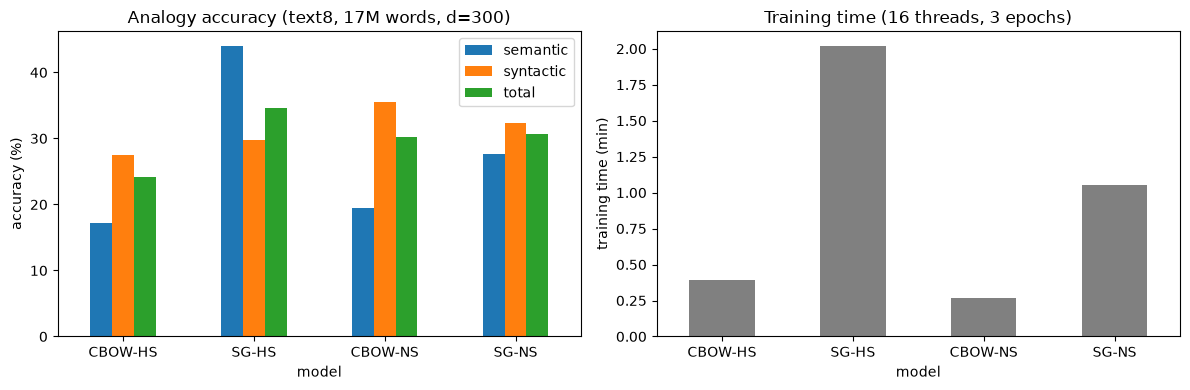

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[["semantic", "syntactic", "total"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("accuracy (%)"); axes[0].set_title(f"Analogy accuracy ({CORPUS}, {n_words/1e6:.0f}M words, d={DIM})")
results["minutes"].plot.bar(ax=axes[1], rot=0, color="gray")
axes[1].set_ylabel("training time (min)"); axes[1].set_title(f"Training time ({WORKERS} threads, {EPOCHS} epochs)")
plt.tight_layout(); plt.savefig(OUT_DIR / "table3_style.png", dpi=120); plt.show()

### 3.3 Per-category breakdown
The single "semantic" number hides a lot. Capitals and nationalities are often easy; currencies are famously hard. Which categories does Skip-gram win?

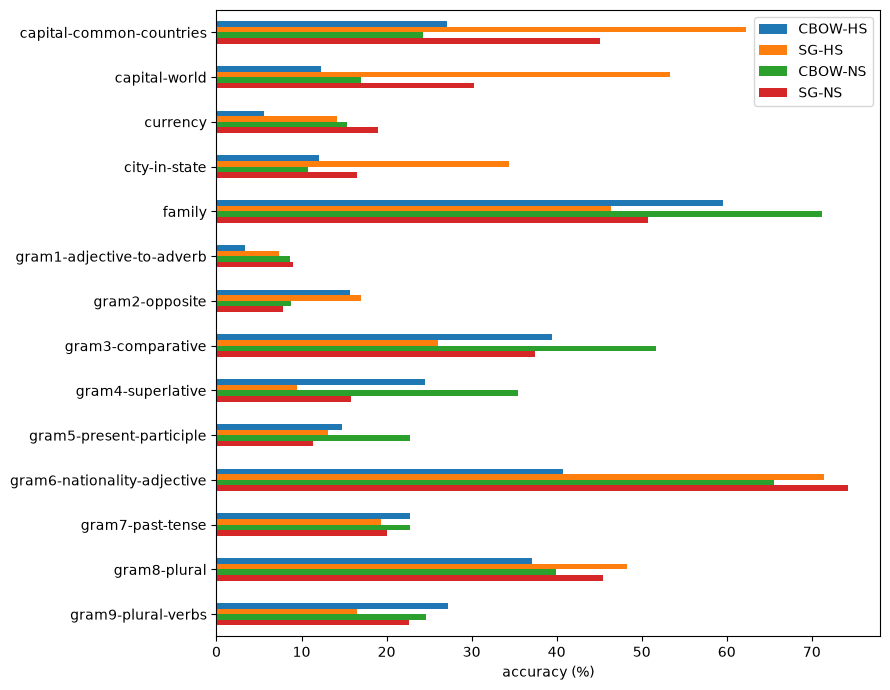

In [8]:
def per_section(wv):
    _, secs = wv.evaluate_word_analogies(QUESTIONS, restrict_vocab=RESTRICT_VOCAB, case_insensitive=True)
    return {s["section"]: 100 * len(s["correct"]) / max(1, len(s["correct"]) + len(s["incorrect"]))
            for s in secs if s["section"] != "Total accuracy"}

per_cat = pd.DataFrame({name: per_section(m.wv) for name, m in models.items()}).round(1)
per_cat.to_csv(OUT_DIR / "per_category.csv")
ax = per_cat.plot.barh(figsize=(9, 7))
ax.set_xlabel("accuracy (%)"); ax.invert_yaxis(); plt.tight_layout()
plt.savefig(OUT_DIR / "per_category.png", dpi=120); plt.show()

### 3.4 *king − man + woman = ?*
`most_similar(positive=[b, c], negative=[a])` answers "a is to b as c is to ?" by looking for the word closest to `b − a + c` (excluding a, b and c themselves — remember that detail, it matters in the twist).

In [9]:
EXAMPLES = [("man", "king", "woman"), ("france", "paris", "italy"), ("big", "bigger", "small"),
            ("walking", "walked", "swimming"), ("einstein", "scientist", "picasso"),
            ("germany", "berlin", "japan"), ("good", "better", "bad"), ("brother", "sister", "son")]
for a, b, c in EXAMPLES:
    row = []
    for name in ["CBOW-HS", "SG-HS", "CBOW-NS", "SG-NS"]:
        wv = models[name].wv
        try:
            ans = wv.most_similar(positive=[b, c], negative=[a], topn=1)[0][0]
        except KeyError:
            ans = "(oov)"
        row.append(f"{name}: {ans}")
    print(f"{a:>9s} : {b:<9s} :: {c:>9s} : ?   ->  " + " | ".join(row))

      man : king      ::     woman : ?   ->  CBOW-HS: vlad | SG-HS: queen | CBOW-NS: queen | SG-NS: queen
   france : paris     ::     italy : ?   ->  CBOW-HS: milan | SG-HS: venice | CBOW-NS: venice | SG-NS: bologna
      big : bigger    ::     small : ?   ->  CBOW-HS: smaller | SG-HS: larger | CBOW-NS: smaller | SG-NS: larger
  walking : walked    ::  swimming : ?   ->  CBOW-HS: brayford | SG-HS: overheard | CBOW-NS: threw | SG-NS: yelled
 einstein : scientist ::   picasso : ?   ->  CBOW-HS: poet | SG-HS: pablo | CBOW-NS: pablo | SG-NS: gogh
  germany : berlin    ::     japan : ?   ->  CBOW-HS: tokyo | SG-HS: tokyo | CBOW-NS: tokyo | SG-NS: tokyo
     good : better    ::       bad : ?   ->  CBOW-HS: bigger | SG-HS: worse | CBOW-NS: worse | SG-NS: worse
  brother : sister    ::       son : ?   ->  CBOW-HS: daughter | SG-HS: daughter | CBOW-NS: daughter | SG-NS: daughter


### 3.5 Table-2-style grid: vector size × amount of data

The paper's Table 2 shows that adding dimensions without adding data (or the other way round) quickly stops helping. We train CBOW-NS (the fastest variant) for every combination of `GRID_DIMS` × `GRID_FRACS` and report total analogy accuracy.

dim   50 |   2.13M words |   2.7s | total acc   2.8%
dim   50 |   4.25M words |   5.0s | total acc   6.1%
dim   50 |   8.50M words |   9.5s | total acc  14.5%
dim   50 |  17.01M words |  18.4s | total acc  24.3%
dim  100 |   2.13M words |   2.6s | total acc   2.9%
dim  100 |   4.25M words |   4.9s | total acc   6.5%
dim  100 |   8.50M words |   9.5s | total acc  17.0%
dim  100 |  17.01M words |  18.1s | total acc  29.2%
dim  300 |   2.13M words |   2.5s | total acc   2.7%
dim  300 |   4.25M words |   4.3s | total acc   6.1%
dim  300 |   8.50M words |   8.1s | total acc  17.3%
dim  300 |  17.01M words |  16.0s | total acc  29.3%
dim  600 |   2.13M words |   2.8s | total acc   2.6%
dim  600 |   4.25M words |   5.0s | total acc   5.9%
dim  600 |   8.50M words |   9.9s | total acc  17.0%
dim  600 |  17.01M words |  20.1s | total acc  29.6%


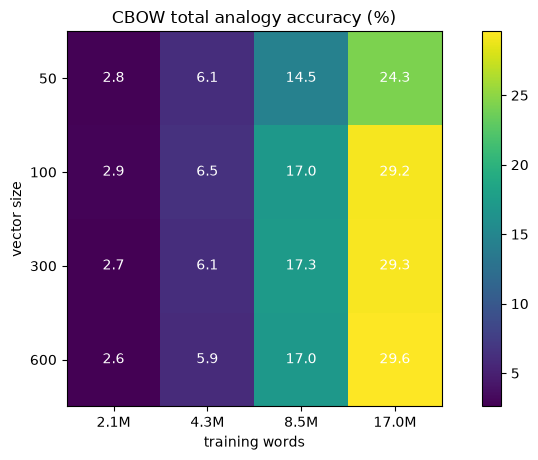

,2.1M,4.3M,8.5M,17.0M
dimensionality,,,,
50,2.8,6.1,14.5,24.3
100,2.9,6.5,17.0,29.2
300,2.7,6.1,17.3,29.3
600,2.6,5.9,17.0,29.6


In [10]:
grid = {}
grid_cfg = dict(CONFIGS["CBOW-NS"])
for d in GRID_DIMS:
    for frac, (p, n) in grid_corpora.items():
        m, secs = train(p, n, vector_size=d, min_count=MIN_COUNT, workers=WORKERS,
                        epochs=GRID_EPOCHS, seed=SEED, **grid_cfg)
        grid[(d, n)] = analogy_scores(m.wv)["total"]
        print(f"dim {d:4d} | {n/1e6:6.2f}M words | {secs:5.1f}s | total acc {grid[(d, n)]:5.1f}%")
        del m

grid_df = pd.Series(grid).unstack().round(1)
grid_df.index.name = "dimensionality"; grid_df.columns = [f"{c/1e6:.1f}M" for c in grid_df.columns]
grid_df.to_csv(OUT_DIR / "table2_style_grid.csv")
fig, ax = plt.subplots(figsize=(1.6 * len(grid_df.columns) + 2, 0.8 * len(grid_df) + 1.5))
im = ax.imshow(grid_df.values, cmap="viridis")
ax.set_xticks(range(len(grid_df.columns)), grid_df.columns); ax.set_yticks(range(len(grid_df)), grid_df.index)
for i in range(grid_df.shape[0]):
    for j in range(grid_df.shape[1]):
        ax.text(j, i, f"{grid_df.values[i, j]:.1f}", ha="center", va="center", color="w")
ax.set_xlabel("training words"); ax.set_ylabel("vector size"); ax.set_title("CBOW total analogy accuracy (%)")
plt.colorbar(im); plt.tight_layout(); plt.savefig(OUT_DIR / "table2_style_grid.png", dpi=120); plt.show()
grid_df

## 4. Twist — what do the vectors learn about gender and jobs?

The paper celebrates that vectors encode relations like *man : king :: woman : queen*. Three years later, **Bolukbasi et al. (2016), "Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings"** ([arXiv:1607.06520](https://arxiv.org/abs/1607.06520)) showed that the very same arithmetic also reproduces social stereotypes, because the vectors mirror the text they were trained on.
Later, **Nissim, van Noord & van der Goot (2020), "Fair is Better than Sensational"** ([arXiv:1905.09866](https://arxiv.org/abs/1905.09866)) pointed out that part of the effect comes from the analogy code itself: `most_similar` is *not allowed* to return the input word, so *man : doctor :: woman : ?* can never answer *doctor*.

The paper never compared its two architectures on this. We ask:
1. **Gender direction.** Following Bolukbasi, we build a *he–she* direction from definitional pairs (he/she, man/woman, …) with PCA, and check how dominant it is.
2. **Occupation projections.** For ~50 job words we measure cosine with that direction (+ = closer to *he*, − = closer to *she*). Do CBOW and Skip-gram agree on which jobs are "male" or "female"? Which one is more biased overall (*DirectBias* = mean |cosine|)?
3. **Analogies, with and without the exclusion trick.** *man : programmer :: woman : ?* — and how often is the honest answer simply the same job?
4. **Seed stability.** If we retrain with a different random seed, do the job rankings stay the same? (If not, single-model bias claims are fragile.)

59 occupation words found in all vocabularies


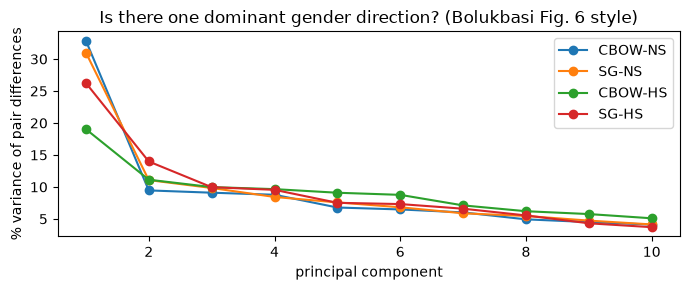

In [11]:
GENDER_PAIRS = [("he", "she"), ("man", "woman"), ("his", "her"), ("him", "her"), ("boy", "girl"),
                ("male", "female"), ("father", "mother"), ("son", "daughter"), ("brother", "sister"),
                ("king", "queen"), ("husband", "wife"), ("men", "women")]
OCCUPATIONS = ["programmer", "engineer", "scientist", "physicist", "mathematician", "chemist", "architect",
               "doctor", "physician", "surgeon", "nurse", "midwife", "teacher", "professor", "librarian",
               "secretary", "receptionist", "clerk", "housekeeper", "maid", "nanny", "homemaker", "dancer",
               "singer", "model", "designer", "hairdresser", "cook", "chef", "baker", "farmer", "carpenter",
               "mechanic", "plumber", "electrician", "pilot", "soldier", "captain", "sailor", "police",
               "lawyer", "judge", "banker", "economist", "manager", "boss", "president", "philosopher",
               "poet", "writer", "novelist", "journalist", "painter", "photographer", "musician", "composer",
               "student", "servant", "prostitute", "nun", "priest", "monk"]


def unit(v):
    return v / np.linalg.norm(v)


def gender_direction(wv, pairs=GENDER_PAIRS):
    """Bolukbasi-style: PCA over the centred definitional pairs; PC1 is the gender direction.
    Returns the direction (oriented so that 'he' is positive) and PC1's share of variance."""
    diffs = []
    for a, b in pairs:
        if a in wv and b in wv:
            va, vb = unit(wv[a]), unit(wv[b]); c = (va + vb) / 2
            diffs += [va - c, vb - c]
    X = np.array(diffs)
    _, S, Vt = np.linalg.svd(X - X.mean(0), full_matrices=False)
    g = Vt[0]
    if g @ (wv["he"] - wv["she"]) < 0:
        g = -g
    return g, (S ** 2 / (S ** 2).sum())


def occupation_projections(wv, g):
    return pd.Series({w: float(unit(wv[w]) @ g) for w in OCCUPATIONS if w in wv})


twist_models = ["CBOW-NS", "SG-NS", "CBOW-HS", "SG-HS"]
gdirs, proj, var_share = {}, {}, {}
for name in twist_models:
    g, ev = gender_direction(models[name].wv)
    gdirs[name], var_share[name] = g, ev
    proj[name] = occupation_projections(models[name].wv, g)
proj = pd.DataFrame(proj).dropna()
print(f"{len(proj)} occupation words found in all vocabularies")

fig, ax = plt.subplots(figsize=(7, 3))
for name in twist_models:
    ax.plot(range(1, 11), var_share[name][:10] * 100, marker="o", label=name)
ax.set_xlabel("principal component"); ax.set_ylabel("% variance of pair differences")
ax.set_title("Is there one dominant gender direction? (Bolukbasi Fig. 6 style)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "gender_pca.png", dpi=120); plt.show()

CBOW-NS    0.084
SG-NS      0.069
CBOW-HS    0.053
SG-HS      0.067

Spearman rank correlation of occupation projections:
         CBOW-NS  SG-NS  CBOW-HS  SG-HS
CBOW-NS     1.00   0.79     0.68   0.66
SG-NS       0.79   1.00     0.62   0.55
CBOW-HS     0.68   0.62     1.00   0.59
SG-HS       0.66   0.55     0.59   1.00


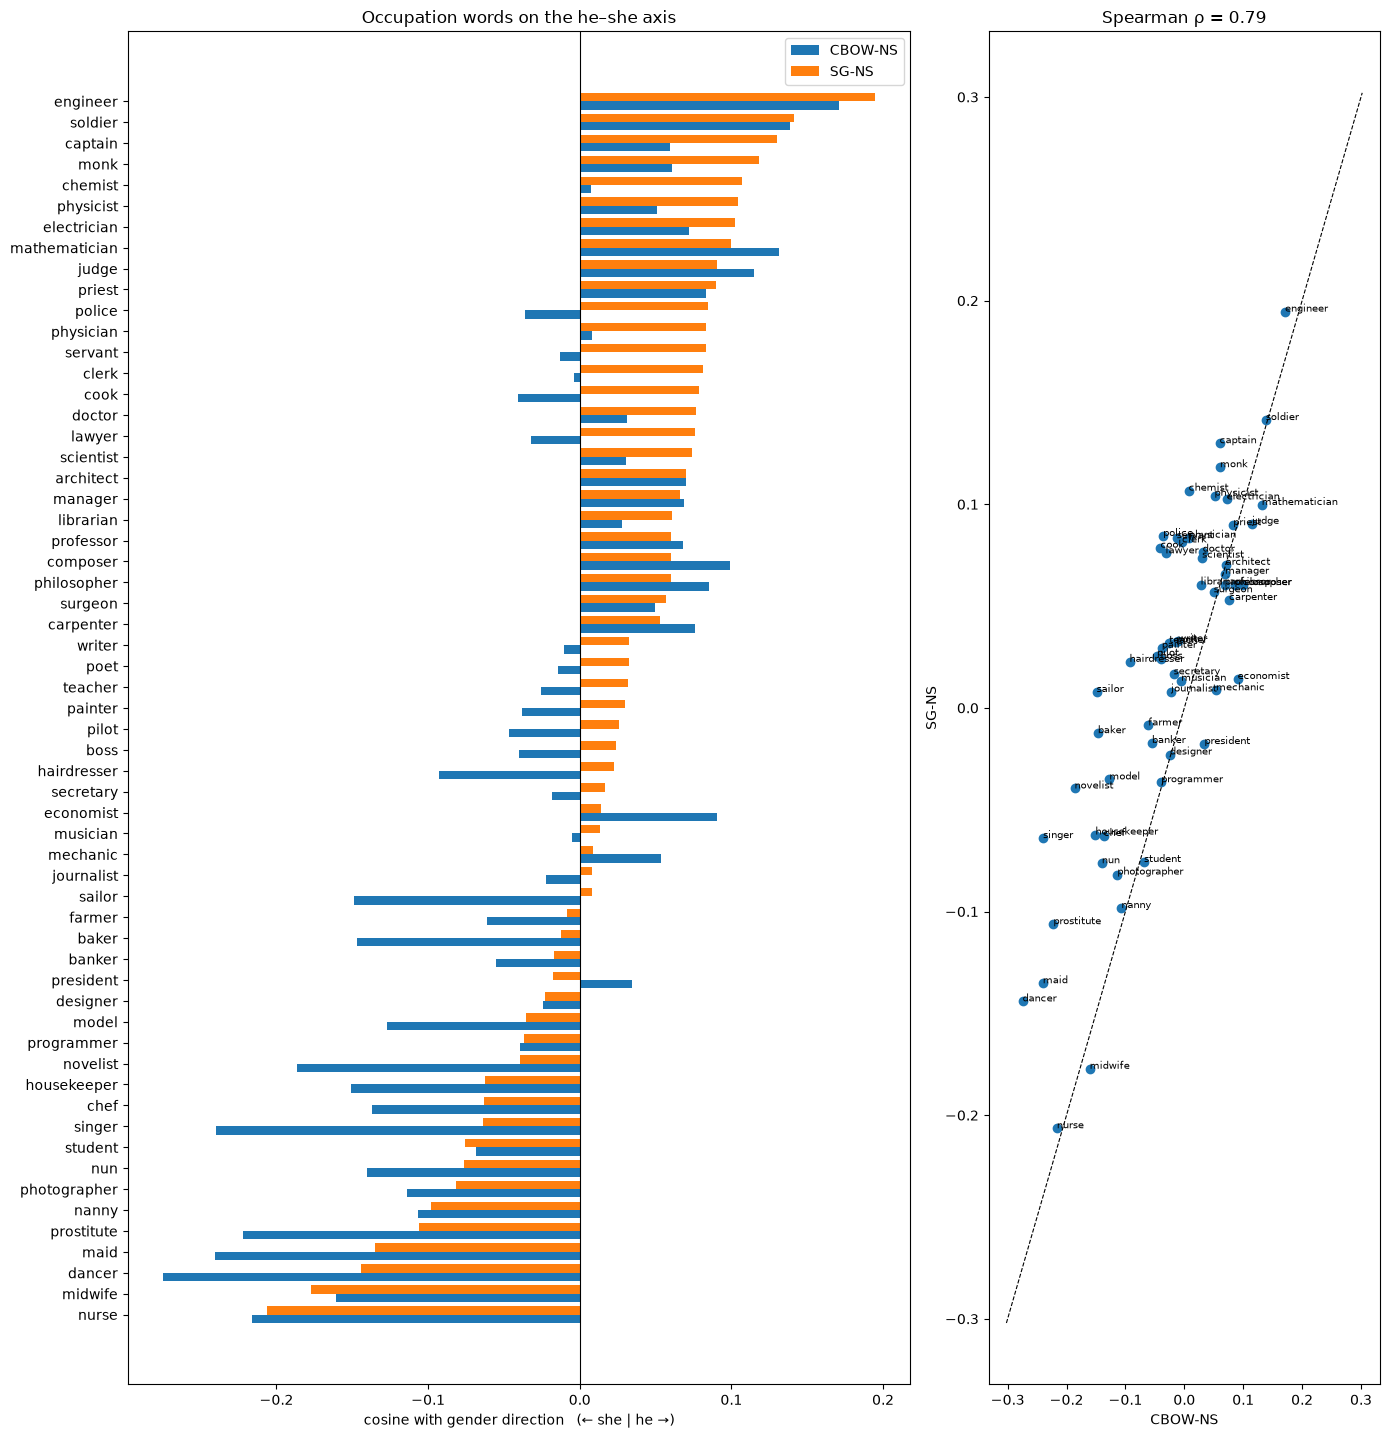

In [12]:
direct_bias = proj.abs().mean().rename("DirectBias (mean |cos|)")
rank_corr = pd.DataFrame(index=twist_models, columns=twist_models, dtype=float)
for a in twist_models:
    for b in twist_models:
        rank_corr.loc[a, b] = spearmanr(proj[a], proj[b])[0]
print(direct_bias.round(3).to_string()); print("\nSpearman rank correlation of occupation projections:")
print(rank_corr.round(2).to_string())

order = proj["SG-NS"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 0.22 * len(order) + 1.5), gridspec_kw=dict(width_ratios=[2, 1]))
y = np.arange(len(order))
axes[0].barh(y - 0.2, proj.loc[order, "CBOW-NS"], height=0.4, label="CBOW-NS")
axes[0].barh(y + 0.2, proj.loc[order, "SG-NS"], height=0.4, label="SG-NS")
axes[0].set_yticks(y, order); axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("cosine with gender direction   (← she | he →)"); axes[0].legend()
axes[0].set_title("Occupation words on the he–she axis")
axes[1].scatter(proj["CBOW-NS"], proj["SG-NS"])
for w in proj.index:
    axes[1].annotate(w, (proj.loc[w, "CBOW-NS"], proj.loc[w, "SG-NS"]), fontsize=7)
lim = proj[["CBOW-NS", "SG-NS"]].abs().max().max() * 1.1
axes[1].plot([-lim, lim], [-lim, lim], "k--", lw=0.8); axes[1].set_xlabel("CBOW-NS"); axes[1].set_ylabel("SG-NS")
axes[1].set_title(f"Spearman ρ = {rank_corr.loc['CBOW-NS', 'SG-NS']:.2f}")
plt.tight_layout(); plt.savefig(OUT_DIR / "occupation_bias.png", dpi=120); plt.show()
proj.round(3).to_csv(OUT_DIR / "occupation_projections.csv")

### 4.1 Analogies: the "exclusion trick"
Left column: the standard answer (input words excluded). Right column: the honest nearest neighbour of `b − a + c`, where the input word *is* allowed to win. If the right column often just repeats the job, the "stereotyped analogy" mostly reflects the evaluation rule rather than a strong gender offset.

In [13]:
PROBES = ["programmer", "doctor", "engineer", "surgeon", "scientist", "boss", "architect", "philosopher",
          "captain", "carpenter", "president", "professor"]

def analogy_both_ways(wv, a, b, c, topn=3):
    excl = [w for w, _ in wv.most_similar(positive=[b, c], negative=[a], topn=topn)]
    target = unit(wv[b]) - unit(wv[a]) + unit(wv[c])
    incl = [w for w, _ in wv.similar_by_vector(target, topn=topn + 2) if w not in (a, c)][:topn]
    return excl, incl

records = []
for name in ["CBOW-NS", "SG-NS"]:
    wv = models[name].wv
    for occ in PROBES:
        if occ not in wv:
            continue
        for a, c in [("man", "woman"), ("woman", "man")]:
            excl, incl = analogy_both_ways(wv, a, occ, c)
            records.append(dict(model=name, question=f"{a}:{occ} :: {c}:?", standard=", ".join(excl),
                                input_allowed=", ".join(incl), returns_same_job=(incl[0] == occ)))
analog = pd.DataFrame(records)
analog.to_csv(OUT_DIR / "gender_analogies.csv", index=False)
print(analog.groupby("model")["returns_same_job"].mean().rename("share where honest answer = same job"))
pd.set_option("display.max_colwidth", 60)
analog

model
CBOW-NS    1.0
SG-NS      1.0
Name: share where honest answer = same job, dtype: float64


,model,question,standard,input_allowed,returns_same_job
0,CBOW-NS,man:programmer :: woman:?,"ada, lovelace, smalltalk","programmer, ada, lovelace",True
1,CBOW-NS,woman:programmer :: man:?,"programmers, configuring, bcpl","programmer, programmers, configuring",True
2,CBOW-NS,man:doctor :: woman:?,"nurse, husband, dentist","doctor, nurse, husband",True
3,CBOW-NS,woman:doctor :: man:?,"daleks, davros, doom","doctor, daleks, davros",True
4,CBOW-NS,man:engineer :: woman:?,"industrialist, inventor, conductor","engineer, industrialist, inventor",True
5,CBOW-NS,woman:engineer :: man:?,"builder, engineers, inventor","engineer, builder, engineers",True
6,CBOW-NS,man:surgeon :: woman:?,"psychiatrist, suffragist, physician","surgeon, psychiatrist, suffragist",True
7,CBOW-NS,woman:surgeon :: man:?,"priestley, stingray, boyle","surgeon, priestley, stingray",True
8,CBOW-NS,man:scientist :: woman:?,"psychiatrist, physicist, geologist","scientist, psychiatrist, physicist",True
9,CBOW-NS,woman:scientist :: man:?,"pioneer, naturalist, engineer","scientist, pioneer, naturalist",True


### 4.2 Seed stability
Same data, same settings, different random seeds. If the Spearman correlations between seeds are much below 1, then "word X is male-biased in this embedding" is partly noise. (Note: with several worker threads gensim is not bit-for-bit deterministic anyway; the seed changes the initial vectors.)

In [14]:
seed_proj = {}
for s in SEEDS_FOR_STABILITY:
    m, _ = train(corpus_path, n_words, **{**BASE, "seed": s}, **CONFIGS["CBOW-NS"])
    g, _ = gender_direction(m.wv)
    seed_proj[f"seed {s}"] = occupation_projections(m.wv, g)
    del m
seed_proj = pd.DataFrame(seed_proj).dropna()
seed_proj[f"seed {SEED}"] = proj["CBOW-NS"]
cols = list(seed_proj.columns)
pairs = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
for a, b in pairs:
    print(f"CBOW-NS {a} vs {b}: Spearman ρ = {spearmanr(seed_proj[a], seed_proj[b])[0]:.2f}")
spread = seed_proj.std(axis=1).sort_values(ascending=False)
print("\nJobs whose projection moves most between seeds:\n", spread.head(8).round(3).to_string())

CBOW-NS seed 1 vs seed 2: Spearman ρ = 0.89
CBOW-NS seed 1 vs seed 3: Spearman ρ = 0.88
CBOW-NS seed 1 vs seed 42: Spearman ρ = 0.90
CBOW-NS seed 2 vs seed 3: Spearman ρ = 0.90
CBOW-NS seed 2 vs seed 42: Spearman ρ = 0.88
CBOW-NS seed 3 vs seed 42: Spearman ρ = 0.89

Jobs whose projection moves most between seeds:
 midwife      0.061
farmer       0.044
model        0.043
nanny        0.042
novelist     0.042
poet         0.042
student      0.038
president    0.038


In [15]:
summary = {
    "quick_mode": QUICK_MODE, "corpus": CORPUS, "words": n_words, "dim": DIM, "epochs": EPOCHS,
    "threads": WORKERS, "notebook_minutes": round((time.perf_counter() - NOTEBOOK_T0) / 60, 1),
}
print(summary)
print(results[["minutes", "semantic", "syntactic", "total"]].to_string())
print("\nDirectBias:", direct_bias.round(3).to_dict())

{'quick_mode': False, 'corpus': 'text8', 'words': 17005207, 'dim': 300, 'epochs': 3, 'threads': 16, 'notebook_minutes': 17.2}
         minutes  semantic  syntactic  total
model                                       
CBOW-HS     0.39     17.13      27.54  24.09
SG-HS       2.02     44.02      29.83  34.55
CBOW-NS     0.27     19.47      35.59  30.24
SG-NS       1.05     27.57      32.31  30.74

DirectBias: {'CBOW-NS': 0.084, 'SG-NS': 0.069, 'CBOW-HS': 0.053, 'SG-HS': 0.067}


## 5. Your findings

*Fill these in after a full run (`QUICK_MODE = False`). Copy the key numbers into this folder's README.*

**Reproduction**
- Semantic vs syntactic accuracy for CBOW and Skip-gram: does the paper's pattern hold on text8? By how much?
- Hierarchical softmax vs negative sampling + subsampling: which mattered more, the architecture or the training trick?
- Training time ratio Skip-gram / CBOW on your laptop vs the paper's ≈3× (Table 5):
- Which analogy categories are hardest? Why might currencies fail on Wikipedia text?
- Table-2 grid: at what point did more dimensions stop helping for a fixed amount of data?

**Twist**
- How dominant is PC1 of the gender pairs? (Bolukbasi found one clear direction on Google News.)
- Which jobs lean most *he* / most *she*? Any surprises?
- CBOW vs Skip-gram: same ranking (ρ = ?) and which has higher DirectBias?
- How often does the honest analogy just return the same job? What does that mean for the "programmer → homemaker" headline?
- Seed stability: is ρ between seeds high enough to trust single-word claims?

**One-sentence takeaway for the repo README:**

> …

## 6. Ideas for further exploration

- **Scale up:** switch `CORPUS = "fil9"` (7× more words) and check whether the CBOW/Skip-gram gap on semantic questions grows or shrinks with data.
- **Compare against the released vectors:** load the official Google News vectors (`gensim.downloader.load("word2vec-google-news-300")`, 1.6 GB) and run the same bias probe — does a 6B-word news corpus encode more or less occupation bias than Wikipedia?
- **Debias and re-test:** implement Bolukbasi's "hard debiasing" (project out the direction for neutral words) and check how much analogy accuracy you lose — then check with Gonen & Goldberg (2019, "Lipstick on a Pig", arXiv 1903.03862) whether the bias is really gone (e.g. by clustering the "debiased" job words).
- **WEAT:** reproduce one Word Embedding Association Test from Caliskan et al. (2017, *Science*) and compare effect sizes between CBOW and Skip-gram.
- **Bridge to LLMs:** the same "linear direction" idea returns in your interpretability strand (linear representation hypothesis, steering vectors). Try finding the he–she direction in GPT-2's residual stream with TransformerLens and compare it with the word2vec one.
- **Other languages:** German has grammatical gender — does a German Wikipedia model separate grammatical from social gender (*Ärztin* vs *Arzt*)?